# Employee Attrition Risk Predictor
Predict whether an employee is likely to leave, using the IBM HR Analytics dataset.

**Steps:** 1) Load data → 2) Explore → 3) Preprocess → 4) Train models → 5) Evaluate → 6) Interpret → 7) Risk scores

## 1. Imports and loading the data

In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)

sns.set_style("whitegrid")

In [5]:
import pandas as pd
import os

# Path to the manually uploaded file in Colab's default working directory
file_path = "WA_Fn-UseC_-HR-Employee-Attrition.csv"

# Verify file exists before loading
if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print(f"Successfully loaded '{file_path}' ({df.shape[0]} rows, {df.shape[1]} columns)")
    display(df.head())
else:
    raise FileNotFoundError(
        f"'{file_path}' was not found. Please verify the filename in the left sidebar under /content/."
    )

Successfully loaded 'WA_Fn-UseC_-HR-Employee-Attrition.csv' (1470 rows, 35 columns)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 2. Exploratory data analysis

In [6]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df['Attrition'].value_counts(normalize=True))
df.describe().T.head(15)

Shape: (1470, 35)
Missing values: 0
Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


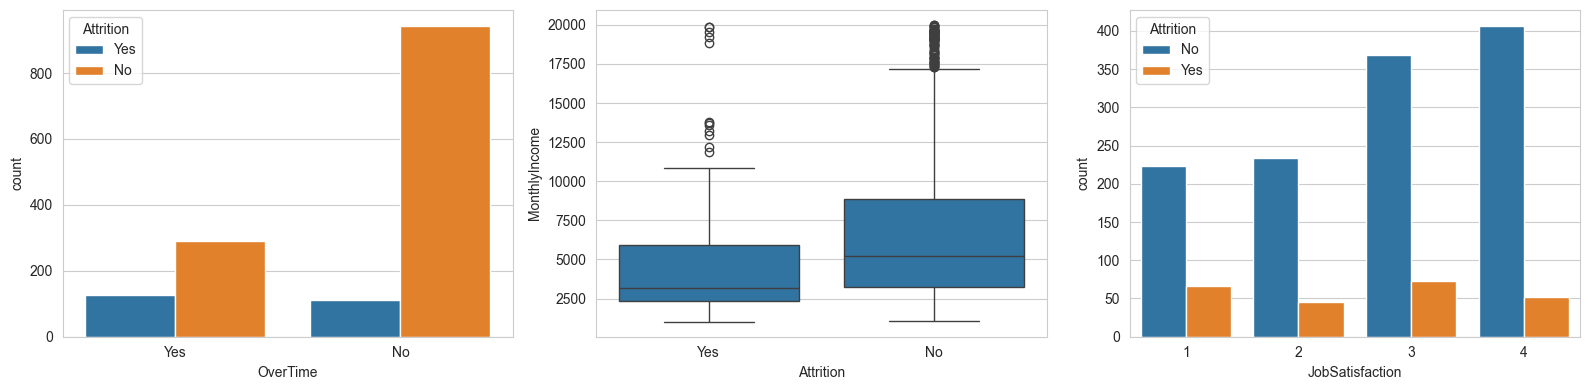

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x='OverTime', hue='Attrition', ax=axes[0])
sns.boxplot(data=df, x='Attrition', y='MonthlyIncome', ax=axes[1])
sns.countplot(data=df, x='JobSatisfaction', hue='Attrition', ax=axes[2])
plt.tight_layout(); plt.show()

## 3. Preprocessing

In [8]:
# Drop columns that carry no information
df = df.drop(columns=['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], errors='ignore')

y = (df['Attrition'] == 'Yes').astype(int)   # 1 = leaves, 0 = stays
X = df.drop(columns='Attrition')

cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

# stratify keeps the same attrition ratio in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(1176, 30) (294, 30)


C:\Users\smile\AppData\Local\Temp\ipykernel_13080\2773985531.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns.tolist()


## 4. Train models
Only ~16% of employees leave (class imbalance), so we use `class_weight='balanced'` to stop the model from just predicting "stays" every time.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                            random_state=42),
}

fitted = {}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
print("Training done.")

Training done.


## 5. Evaluation (don't rely on accuracy alone!)

In [10]:
for name, pipe in fitted.items():
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    print(f"===== {name} =====")
    print(classification_report(y_test, pred, target_names=['Stays', 'Leaves']))
    print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3), "\n")

===== Logistic Regression =====
              precision    recall  f1-score   support

       Stays       0.92      0.77      0.84       247
      Leaves       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294

ROC-AUC: 0.803 

===== Random Forest =====
              precision    recall  f1-score   support

       Stays       0.85      0.99      0.92       247
      Leaves       0.62      0.11      0.18        47

    accuracy                           0.85       294
   macro avg       0.74      0.55      0.55       294
weighted avg       0.82      0.85      0.80       294

ROC-AUC: 0.79 



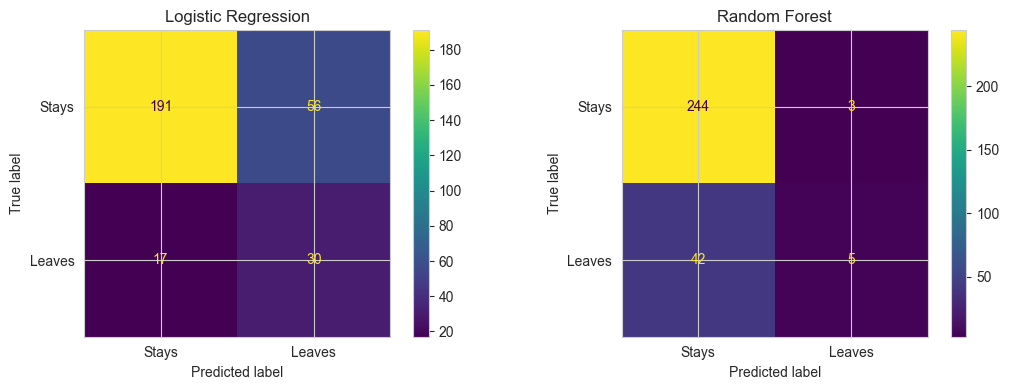

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test,
                                          display_labels=['Stays', 'Leaves'], ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.show()

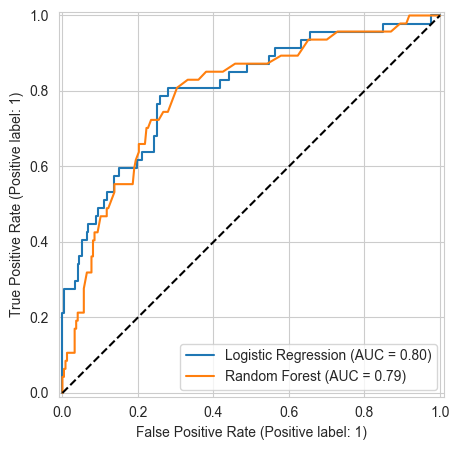

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--'); plt.show()

## 6. What drives attrition? (feature importance)

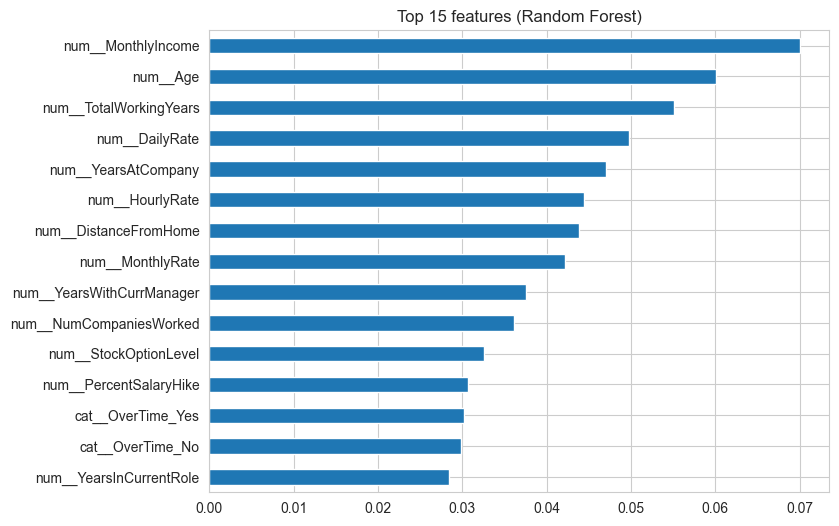

In [13]:
rf = fitted["Random Forest"]
names = rf.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf.named_steps['model'].feature_importances_, index=names).sort_values(ascending=False).head(15)

imp.sort_values().plot(kind='barh', figsize=(8, 6), title='Top 15 features (Random Forest)')
plt.show()

## 7. The risk predictor

In [14]:
best = fitted["Logistic Regression"]
risk = best.predict_proba(X_test)[:, 1]

results = X_test.copy()
results['Risk Score'] = risk.round(3)
results['Risk Level'] = pd.cut(risk, bins=[0, 0.3, 0.6, 1.0],
                               labels=['Low', 'Medium', 'High'], include_lowest=True)
results['Actually Left'] = y_test.values

results.sort_values('Risk Score', ascending=False)[
    ['Age', 'JobRole', 'OverTime', 'MonthlyIncome', 'Risk Score', 'Risk Level', 'Actually Left']].head(10)

,Age,JobRole,OverTime,MonthlyIncome,Risk Score,Risk Level,Actually Left
357,21,Sales Representative,Yes,2174,0.992,High,1
911,25,Sales Representative,Yes,1118,0.987,High,1
688,19,Sales Representative,Yes,2121,0.967,High,1
946,40,Sales Executive,Yes,9094,0.959,High,1
1021,25,Sales Representative,No,4400,0.958,High,1
762,26,Research Scientist,Yes,2042,0.953,High,1
132,31,Sales Executive,Yes,4559,0.943,High,1
514,33,Research Scientist,Yes,3348,0.933,High,1
525,24,Sales Executive,No,4577,0.923,High,1
829,33,Sales Executive,Yes,8224,0.906,High,1


In [15]:
# Predict for ONE new employee: edit the values below
new_emp = X_test.iloc[[0]].copy()
new_emp['OverTime'] = 'Yes'
new_emp['MonthlyIncome'] = 2500
print("Attrition risk:", round(best.predict_proba(new_emp)[0, 1] * 100, 1), "%")

Attrition risk: 67.1 %


In [16]:
results['Risk Level'].value_counts()

Risk Level
Low       160
Medium     72
High       62
Name: count, dtype: int64